# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it uses pyKinGenie's one-site fitter and compares its output with the author report. No data download is required.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import display

# Works from the repository root, notebooks/ or docs/notebooks/.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "src" / "pykingenie").is_dir())
sys.path[:0] = [str(repo_root / "src"), str(repo_root / "notebooks")]

from pykingenie import KineticsAnalyzer, read_info_sheet
from pykingenie.utils.plotting import plot_association_dissociation, plot_traces_all
from notebook_helpers import show_plotly_static

data_folder = repo_root / "notebooks" / "data" / "spr_exports"
fit_metadata = json.loads((data_folder / "fit_metadata.json").read_text())

## File layout and published five-curve selection

Tab-separated X/Y pairs for **cycles 18–22**, the five curves shown on page 1
of the author sensorgram report. Their concentrations are **221.7, 443.4,
886.8, 1774, 3547 nM**, verified against that figure and the original sample sheet.
The original labels include mass/truncated units; molar values are supplied
explicitly from the source metadata.

Retain all finite observations in the author protocol window **−60 to 780 s**,
at native sampling. Counts are **8,221 / 8,391 / 8,400 / 8,392 / 8,400**.
The original has 179, 9, 0, 8, 0 missing/non-finite pairs, respectively; only
those pairs are omitted, together with 16 observations outside the protocol
window. Missing values are not interpolated or replaced. The Windows-1252
source is transcoded to UTF-8 without changing its decoded labels or values.

Association is `[0, 180)` s; dissociation is 180–780 s, from the original sample
sheet. The raw plot rejoins all partitions on each original time grid.
`sample_id` is the analyte identity from that sheet.

## Import with the companion Data Info Sheet

The TitrationAnalysis sample sheet that accompanies the export supplies the
association window (`Bsl Start` + `Baseline`, then `Association`), the molar
concentrations and the analyte (`sample_id`). `read_info_sheet` shows how pyKinGenie
reads it.

The sheet lists all eight concentrations of the run, but this excerpt holds
only cycles 18–22, so their five concentrations are passed explicitly.

`pyKinetics.load` detects the file format (`spr_text`), reads the file with `SprTextExperiment.read_file` and adds the experiment to the analyzer; the keyword options go to that reader.

In [2]:
data_file = data_folder / "biacore_cycle_sample.tsv"
info_file = data_folder / "metadata" / "Example T200 Data Info Sheet.xlsx"
display(read_info_sheet(info_file))

pyKinetics = KineticsAnalyzer()
experiment = pyKinetics.load(
    data_file,
    info=info_file,
    concentrations=fit_metadata["biacore_cycle_sample"]["concentrations"],  # µM
)
experiment.ligand_conc_df

,Included,Block,Position,Analyte,Ligand,Baseline_start_s,Baseline_s,Association_s,Dissociation_s,Association_skip_s,Dissociation_skip_s,Concentrations_micromolar,Included_concentrations_micromolar,Bulk_shift,Regeneration,Baseline_correction,Global_Rmax
0,True,1,2,AE.A244,CH31,-60.0,60.0,180.0,600.0,0.0,0.0,"[0.02771, 0.05543, 0.1109, 0.2217, 0.4434, 0.8...",None,True,True,False,False
1,True,1,2,AE.A244,CH31,-60.0,60.0,180.0,600.0,0.0,0.0,"[0.02771, 0.05543, 0.1109, 0.2217, 0.4434, 0.8...",None,True,True,False,True


,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment
0,Cycle: 18 AE.A244 12.5,1,0.2217,AE.A244,1,0,biacore_cycle_sample
1,Cycle: 19 AE.A244 25 µg,1,0.4434,AE.A244,1,0,biacore_cycle_sample
2,Cycle: 20 AE.A244 50 µg,1,0.8868,AE.A244,1,0,biacore_cycle_sample
3,Cycle: 21 AE.A244 100 µ,1,1.7740,AE.A244,1,0,biacore_cycle_sample
4,Cycle: 22 AE.A244 200 µ,1,3.5470,AE.A244,1,0,biacore_cycle_sample


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

## Imported sensorgrams

All retained observations at their original times, before alignment.

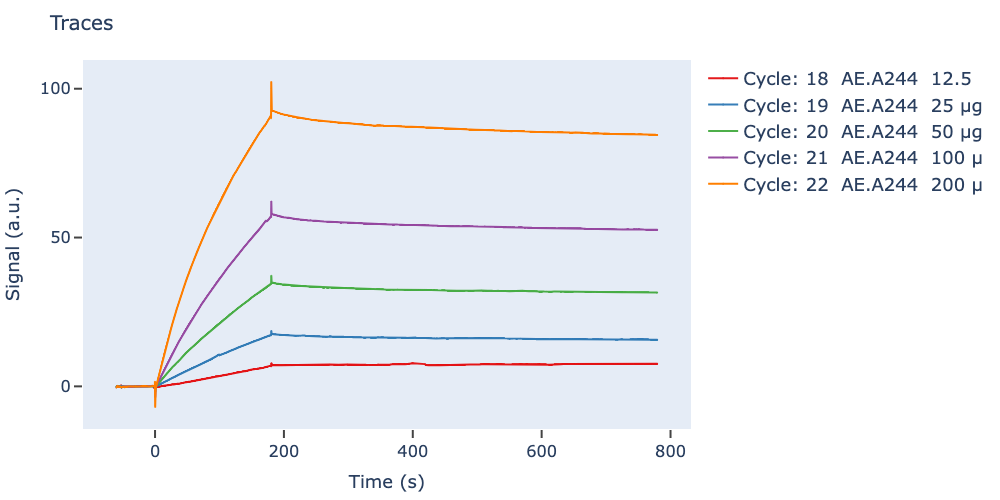

In [3]:
show_plotly_static(plot_traces_all(pyKinetics, pyKinetics.get_legends_table()),
                   width=1000, height=500, scale=1)

## Published one-site model

The original T200 sample sheet specifies association **0–180 s**, dissociation
**180–780 s**, regeneration, and association bulk shifts. Fit a **one-site
Langmuir model with local Smax**, using pyKinGenie's existing fitter. The
author report uses fitting #1 with local Rmax and bulk-shift handling. The
existing pyKinGenie one-site method does not fit independent RI offsets,
so its settings differ from the reference. The selected cycles
18–22 have concentrations **0.2217, 0.4434, 0.8868, 1.774, 3.547 µM**,
matching page 1 of the author sensorgram report.

Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/) and the [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv). The original CSV is included locally with provenance in [SOURCES.md](data/spr_exports/SOURCES.md).

This notebook fits the **same five concentration curves** as the author report,
within the same nominal protocol windows. No alternative models or model selection are run.

## Align and fit with `KineticsAnalyzer`

`align_association` subtracts the mean of the last 10 baseline points.
`generate_fittings` builds one fitter per sample, `submit_steady_state_fitting`
provides the starting values and `submit_kinetics_fitting` runs the one-site
association/dissociation model on every observation (`trim_time=0`).

In [4]:
experiment.align_association(npoints=10)

pyKinetics.merge_ligand_conc_df()
pyKinetics.generate_fittings(pyKinetics.combined_ligand_conc_df, trim_time=0)
pyKinetics.submit_steady_state_fitting()
pyKinetics.submit_kinetics_fitting(fitting_model="one_to_one", shared_smax=False)

pyKinetics.get_fitting_results()
pyKinetics.fit_params_kinetics_all

,Concentration [µM],Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s],Name
0,0.2217,0.071797,0.000128,109.774702,0.001776,AE.A244
1,0.4434,0.071797,0.000128,128.871072,0.001776,AE.A244
2,0.8868,0.071797,0.000128,138.375687,0.001776,AE.A244
3,1.7740,0.071797,0.000128,130.666647,0.001776,AE.A244
4,3.5470,0.071797,0.000128,133.473911,0.001776,AE.A244


## One-site fit from pyKinGenie

The package's `plot_association_dissociation` displays observations and the
fitted curves. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Sensorgram_Example.pdf).
Locate Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. The same five concentrations are shown on **page 1** of that report.

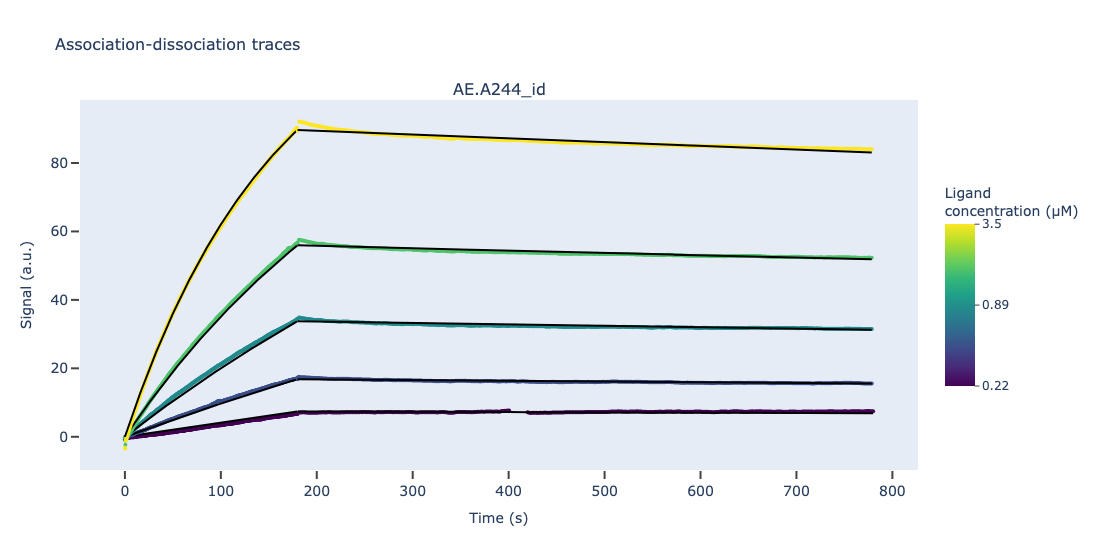

In [5]:
show_plotly_static(plot_association_dissociation(pyKinetics, split_by_smax_id=False),
                   width=1100, height=550, scale=1)

## Compare pyKinGenie's fitted parameters with the published values

The table uses `fitter.Kd` and `fitter.k_off` directly. kon is their ratio.
Only unit conversion and percentage differences are calculated below.
Local Smax values are shown in the library result table above.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv).
Use Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. These are the values in the Published column below.

In [6]:
fitter = pyKinetics.fittings[pyKinetics.fittings_names[0]]
reference = fit_metadata[experiment.name]["literature_reference"]["parameters_molar"]

comparison = pd.DataFrame(
    {"Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
     "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3]},
    index=["kon (M⁻¹ s⁻¹)", "koff (s⁻¹)", "Kd (nM)"],
)
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
comparison.style.format("{:.4g}")

,Published,pyKinGenie,Difference (%)
kon (M⁻¹ s⁻¹),1812,1776,-1.991
koff (s⁻¹),0.0001191,0.0001275,7.046
Kd (nM),65.74,71.8,9.221


## Scope of the comparison

These are the results of pyKinGenie's existing fitting API. Both analyses now
use the same five curve identities, concentrations and nominal association/
dissociation windows; those selections were verified against page 1 of the
author sensorgram report and the companion sample sheet.

Differences in alignment, sampling, time handling and model settings remain.
The standard method does not add the author's T200 bulk-shift parameters or
reconstruct Carterra's absolute occupied state/full non-regenerative history.
The comparison table shows the library results without custom corrections.
Matching the curve selection therefore does not imply an exact reproduction
or validate intrinsic kinetic constants.

See [SPR_FITTING.md](SPR_FITTING.md) for API calls and reference reports.